In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'tensorflow', 'keras', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'keras': 'keras==3.14.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'tensorflow' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'tensorflow' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'tensorflow.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Efficient Convnets

The networks of the previous sections were designed to win accuracy
benchmarks, and they were trained and run on datacenter GPUs. Many
convolutional networks run elsewhere: on phones, cameras, cars, and embedded
boards. There latency, memory, and energy are fixed budgets, and a network
that exceeds them cannot ship, however accurate it is. A phone that
classifies every frame its camera records is a simple example. VGG-16 needs
15.3 billion multiply-adds to classify one $224 \times 224$ image, so at 30
frames a second the phone would have to perform 460 billion multiply-adds per
second. The network's 138 million parameters would occupy 550 MB in single
precision, in memory next to every other app. How can we make a
convolutional network an order of magnitude cheaper, and what does that cost
in accuracy?

This section studies three ideas that make convnets cheaper.
*Factorization* replaces each dense convolution by a per-channel spatial
filter and a $1 \times 1$ channel mixer. *Scaling and search* fixes the block
and lets an optimizer choose the widths, depths, and input resolution.
*Re-parameterization* trains a network with several branches per layer and
then merges the branches into a single convolution that computes the same
function. We will also see the limit of the first idea: on a GPU, a network
with 7.7 times fewer multiply-adds is not 7.7 times faster.

In [ ]:
import math
import numpy as np
import tensorflow as tf
from d2l import tensorflow as d2l

In [ ]:
import time

## Depthwise-Separable Networks

### MobileNet

Most of the arithmetic of a convnet is spent in its dense convolutions, so
the first idea makes each of them cheaper. A dense $k \times k$ convolution
from $c_\textrm{i}$ to $c_\textrm{o}$ channels on an $h \times w$ output
performs $hw \cdot c_\textrm{i} c_\textrm{o} k^2$ multiply-adds: every output
channel filters every input channel. A *depthwise-separable* convolution
(that section) splits this work in two. A *depthwise*
$k \times k$ convolution filters each input channel on its own, and a
*pointwise* $1 \times 1$ convolution then mixes the channels at each
position. The two stages cost $hw \cdot c_\textrm{i} k^2$ and
$hw \cdot c_\textrm{i} c_\textrm{o}$ multiply-adds, so relative to the dense
layer the separable pair costs (the equation)

$$
\frac{hw \cdot c_\textrm{i} k^2 + hw \cdot c_\textrm{i} c_\textrm{o}}
{hw \cdot c_\textrm{i} c_\textrm{o} k^2}
= \frac{1}{c_\textrm{o}} + \frac{1}{k^2}.
$$

The same fraction holds for the weights. For $3 \times 3$ kernels and 128
output channels it is $1/128 + 1/9 \approx 0.119$: the separable layer is
8.4 times cheaper, and no number of output channels makes it more than 9
times cheaper.

MobileNet [@howard2017mobilenet] turned this layer into a whole
network. Every layer after the first is the block of
the figure: a depthwise $3 \times 3$ convolution and a
pointwise $1 \times 1$ convolution, each followed by batch normalization and
a ReLU. The network downsamples by giving the depthwise convolution a stride
of 2, so it needs no pooling layers inside, and it ends with global average
pooling and one linear layer, as NiN does (that section). A single
*width multiplier* scales every channel count, so that one network design
yields a family of networks that trade accuracy against cost. On ImageNet,
MobileNet comes within one point of VGG-16's accuracy (70.6% against 71.5%)
with 0.57 billion multiply-adds and 4.2 million parameters: 27 times less
arithmetic and 33 times fewer parameters.

![A depthwise-separable block from $c_\textrm{i}$ to $c_\textrm{o}$ channels. The depthwise $3 \times 3$ convolution filters each input channel separately; the pointwise $1 \times 1$ convolution mixes the channels at each position; batch normalization and a ReLU follow each convolution.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/arch-dws-block.svg)

### The Inverted Bottleneck

The bottleneck blocks of ResNet and ResNeXt (that section)
compress: a $1 \times 1$ convolution reduces a wide representation, the
$3 \times 3$ convolution works in the narrow space, and a final $1 \times 1$
convolution expands it back. This is the right trade when the $3 \times 3$
convolution is dense and therefore expensive. Once the spatial convolution
is depthwise, it is cheap even on wide tensors, and the trade reverses.
MobileNetV2 [@sandler2018mobilenetv2] therefore *inverts* the
bottleneck: the residual stream stays thin, a $1 \times 1$ convolution
expands it (by a factor of 6 in the paper), the depthwise $3 \times 3$
convolution operates in the wide expanded space, and a $1 \times 1$
projection returns to the thin stream. No ReLU follows the projection: a
ReLU applied to a low-dimensional representation zeroes the negative
coordinates and with them information that later layers cannot recover, and
the paper's ablations favor the linear projection. The residual connection
joins the thin ends, so the tensors that stay in memory from one block to
the next are the small ones. On a phone, activation memory rather than
parameter storage is often the binding constraint. The same block shape,
with a $7 \times 7$ depthwise convolution moved to the front, reappears in
the ConvNeXt network later in this chapter.

### A Mini-MobileNet

We build a small MobileNetV1-style network for Fashion-MNIST. We use the
original block rather than the inverted bottleneck because it shows the
factorization most directly. The function below builds the pair of
the figure; a stride of 2 downsamples. Every convolution in the
networks of this section is followed by batch normalization, which has its
own shift, so the convolutions carry no bias. We initialize all
convolution and linear weights with the He initialization of
that section, a normal distribution with variance
$2/n_\textrm{in}$, where $n_\textrm{in}$ is the number of inputs to each
unit.

In [2]:
def he_init():
    """Normal weights with variance 2/n_in; one instance per layer."""
    return tf.keras.initializers.VarianceScaling(2.0, 'fan_in',
                                                 'untruncated_normal')

def dws_block(out_channels, strides=1):
    """Depthwise 3x3 and pointwise 1x1 convolutions, each with BN and ReLU."""
    return tf.keras.Sequential([
        tf.keras.layers.ZeroPadding2D(1),  # Pad 1 on every side
        tf.keras.layers.DepthwiseConv2D(  # Each unit sees n_in = 3 x 3 inputs
            3, strides, use_bias=False,
            depthwise_initializer=tf.keras.initializers.RandomNormal(
                stddev=math.sqrt(2 / 9))),
        tf.keras.layers.BatchNormalization(momentum=0.9, epsilon=1e-5),
        tf.keras.layers.ReLU(),
        tf.keras.layers.Conv2D(out_channels, 1, use_bias=False,
                               kernel_initializer=he_init()),
        tf.keras.layers.BatchNormalization(momentum=0.9, epsilon=1e-5),
        tf.keras.layers.ReLU()])

Like VGG (that section), the whole network is a list of block parameters,
here (channels, stride) pairs. A $3 \times 3$ convolution with stride 2 lifts
the grayscale input to 32 channels at half resolution; seven
depthwise-separable blocks then double the channels three times while halving
the feature map three times; global average pooling and a linear layer produce
the class scores. We train with stochastic gradient descent with momentum 0.9,
which steps along an exponentially weighted sum of recent gradients instead of
the latest gradient alone; when successive gradients agree, its steps are about
$1/(1-0.9) = 10$ times longer than plain gradient steps at the same rate
(that section treats momentum fully). This optimizer, whose
momentum lengthens its steps, is stronger than the plain SGD of
that section, so the accuracies below are not comparable with
ResNet-18's there. As for the networks of this chapter since AlexNet
(that section), the learning rate decays to zero along a half cosine,
here without warmup: it starts at `lr` and reaches zero after the `num_steps`
minibatches of training (4,690 for 10 epochs). With a constant rate the test
accuracy wobbles by one to three points from epoch to epoch; the decay makes
the accuracy at the end of training reproducible. The schedule is a built-in
of the framework.

In [3]:
class MiniMobileNet(d2l.Classifier):
    def __init__(self, arch=((64, 1), (128, 2), (128, 1), (256, 2), (256, 1),
                             (512, 2), (512, 1)),
                 lr=0.05, num_steps=4690, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = tf.keras.Sequential([
            tf.keras.layers.ZeroPadding2D(1),
            tf.keras.layers.Conv2D(32, 3, 2, use_bias=False,
                                   kernel_initializer=he_init()),
            tf.keras.layers.BatchNormalization(momentum=0.9, epsilon=1e-5),
            tf.keras.layers.ReLU()])
        for c_out, strides in arch:
            self.net.add(dws_block(c_out, strides))
        self.net.add(tf.keras.layers.GlobalAvgPool2D())
        self.net.add(tf.keras.layers.Dense(num_classes,
                                           kernel_initializer=he_init()))

    def configure_optimizers(self):
        schedule = tf.keras.optimizers.schedules.CosineDecay(self.lr,
                                                             self.num_steps)
        return tf.keras.optimizers.SGD(schedule, momentum=0.9)

How many parameters does the network have, and how many would it need with
dense convolutions? Counting the trainable parameters answers the first
question; we save the count as `num_params` for later sections.

In [4]:
def num_params(model):
    """The number of trainable parameters."""
    return sum(int(tf.size(w)) for w in model.trainable_variables)

model = MiniMobileNet()
assert model(tf.zeros((1, 96, 96, 1))).shape == (1, 10)
num_params(model)

542474

The network has 542,474 parameters. A twin that replaced each separable pair by
one dense $3 \times 3$ convolution between the same channel counts would need
$9 \sum_l c_{\textrm{i},l}\, c_{\textrm{o},l} = 4{,}663{,}296$ weights in its
seven blocks alone, 8.8 times the 530,528 weights of the separable
convolutions. This is the ratio $1/c_\textrm{o} + 1/k^2$ predicts for these
channel counts.

### Arithmetic, Accuracy, and Time

Does the factorization give up accuracy? To find out, we compare the
mini-MobileNet with a dense VGG-style network (that section) that has
about the *same number of parameters*. Dense $3 \times 3$ convolutions spend
parameters about nine times faster per pair of channel counts, so the dense
network stops at 128 channels where the separable one reaches 512. Both
networks use batch normalization after every convolution, the same
initialization, the same global-average-pooling head, the same optimizer, and
the same training budget. The comparison therefore matches parameters, not
architectures: the separable block and the wider channels it allows change
together.

In [5]:
class VGGSmall(d2l.Classifier):
    """A dense VGG-style network with the same parameter budget."""
    def __init__(self, arch=((2, 32), (2, 64), (2, 128), (2, 128)),
                 lr=0.05, num_steps=4690, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = tf.keras.Sequential()
        for num_convs, c_out in arch:
            for _ in range(num_convs):
                self.net.add(tf.keras.layers.Conv2D(
                    c_out, 3, padding='same', use_bias=False,
                    kernel_initializer=he_init()))
                self.net.add(tf.keras.layers.BatchNormalization(
                    momentum=0.9, epsilon=1e-5))
                self.net.add(tf.keras.layers.ReLU())
            self.net.add(tf.keras.layers.MaxPool2D(2))
        self.net.add(tf.keras.layers.GlobalAvgPool2D())
        self.net.add(tf.keras.layers.Dense(num_classes,
                                           kernel_initializer=he_init()))

    def configure_optimizers(self):
        schedule = tf.keras.optimizers.schedules.CosineDecay(self.lr,
                                                             self.num_steps)
        return tf.keras.optimizers.SGD(schedule, momentum=0.9)

Before training, we count the arithmetic. A convolution with "same"
padding and stride $s$ turns an $h \times h$ input into an output of side
$\lceil h/s \rceil$, and each output position of each output channel costs
$k^2 c_\textrm{i} / g$ multiply-adds for a convolution with $g$ groups. The
functions below add these costs up for both networks on $96 \times 96$
inputs, including the linear head.

In [6]:
def conv_macs(h, c_in, c_out, k=3, stride=1, groups=1):
    """Output side and multiply-adds of a k x k convolution, 'same' padding."""
    h = -(-h // stride)  # ceil(h / stride)
    return h, h * h * k * k * c_in * c_out // groups

def mobilenet_macs(arch, h=96, num_classes=10):
    h, total = conv_macs(h, 1, 32, stride=2)  # The stem
    c = 32
    for c_out, stride in arch:
        h, depthwise = conv_macs(h, c, c, stride=stride, groups=c)
        h, pointwise = conv_macs(h, c, c_out, k=1)
        total, c = total + depthwise + pointwise, c_out
    return total + c * num_classes

def vgg_macs(arch, h=96, num_classes=10):
    total, c = 0, 1
    for num_convs, c_out in arch:
        for _ in range(num_convs):
            h, macs = conv_macs(h, c, c_out)
            total, c = total + macs, c_out
        h //= 2  # 2 x 2 max-pooling
    return total + c * num_classes

macs = {'Mini-MobileNet': mobilenet_macs(MiniMobileNet().arch),
        'VGG-style': vgg_macs(VGGSmall().arch)}
macs, macs['VGG-style'] / macs['Mini-MobileNet']

({'Mini-MobileNet': 50259968, 'VGG-style': 384861440}, 7.657415142007253)

At about the same parameter count, the dense network performs 385 million
multiply-adds per image and the separable one 50 million, 7.7 times fewer.
The dense network spends most of its multiply-adds in its first three
stages, on feature maps of 96 to 24 pixels on a side, where each weight is
applied at thousands of positions. MobileNet holds nearly three quarters of its
weights in the pointwise convolutions of its last two blocks, which see
only $6 \times 6$ feature maps.

We now train both networks for 10 epochs on Fashion-MNIST, upsampled to
$96 \times 96$ pixels as for the networks of the previous sections.

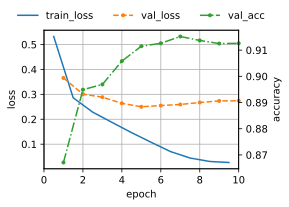

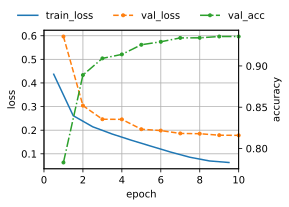

In [7]:
data = d2l.FashionMNIST(batch_size=128, resize=(96, 96))
models, accuracy = {}, {}
num_steps = 10 * len(data.train_dataloader())  # 10 epochs of 469 steps
for name, cls in (('Mini-MobileNet', MiniMobileNet),
                  ('VGG-style', VGGSmall)):
    models[name] = cls(lr=0.05, num_steps=num_steps)
    trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
    trainer.fit(models[name], data)
    accuracy[name] = trainer.history['val_acc'][-1]

Multiply-adds count arithmetic, not time. To see how they translate into
time, we measure how long one forward pass takes on a batch of 128 images,
the work of inference, on the GPU. As in that section,
we run the computation once to warm up, repeat it, and wait for the GPU to
finish before reading the clock.

In [ ]:
def forward_ms(model, num_reps=50):
    """Milliseconds per forward pass of a batch of 128 images."""
    X = tf.random.normal((128, 96, 96, 1))
    @tf.function
    def forward(X):
        return model(X, training=False)
    forward(X).numpy()  # Trace, warm up, and wait
    start = time.perf_counter()
    for _ in range(num_reps):
        Y = forward(X)
    Y.numpy()  # Wait for the GPU
    return 1000 * (time.perf_counter() - start) / num_reps

for name, model in models.items():
    print(f'{name}: {num_params(model):,} parameters, '
          f'{macs[name] / 1e6:.1f}M multiply-adds, '
          f'accuracy {accuracy[name]:.3f}, '
          f'{forward_ms(model):.1f} ms/batch')

the table collects the results. The accuracies are the range
over repeated runs, and the time ratio is the range of the VGG-style network's
forward time divided by the mini-MobileNet's.

:Mini-MobileNet against a dense VGG-style network with about the same number
of parameters (Fashion-MNIST at $96 \times 96$, 10 epochs; test accuracy and
forward-pass time ratio over repeated runs).

| Model | Parameters | Multiply-adds | Test accuracy | Forward time |
|---|---:|---:|---:|---:|
| Mini-MobileNet | 542,474 | 50.3 million | 91–92% | 1 |
| VGG-style | 583,594 | 384.9 million | 93.5–94% | 2–3.5 |

At the same parameter budget the dense network is about two points more
accurate, and it spends 7.7 times as much arithmetic to get there. Part of
the gap is the restriction of the separable layer: it can only express
kernels in which every output channel sees the same spatial filter of each
input channel, scaled by a channel weight. Part is arithmetic itself: the
dense network applies each weight at far more positions, keeping
$96 \times 96$ feature maps for its first two convolutions where MobileNet
halves the resolution in its stem. Equal parameters are therefore not equal
compute. The ImageNet comparison of MobileNet with VGG-16 above was a
different one: nearly equal accuracy at 33 times fewer parameters and 27
times less arithmetic.

Matching the arithmetic instead shows what the separable network buys. With
MobileNet's 50 million multiply-adds, the dense network would have to shrink
every width by about 2.8, to 11, 23, 46, and 46 channels (49 million
multiply-adds) and 76,000 parameters, while the separable network spends the
same arithmetic on up to 512 channels and seven times as many parameters.
Efficient architectures accept the restriction of the separable layer and
spend the savings on more channels; the exercises measure what that buys in
accuracy.

The time differs by much less than the arithmetic. A dense $3 \times 3$
convolution with $c_\textrm{o}$ output channels performs $9 c_\textrm{o}$
multiply-adds for every input value it reads, enough to keep a GPU's arithmetic
units busy. A depthwise convolution performs 9, and a GPU then spends most of
the layer's time moving activations to and from memory. Operation counts are a
proxy for time; how good a proxy depends on the hardware, which is the theme of
the rest of this section.

## Scaling and Searching

MobileNet fixes a block and chooses the channel counts by hand. Two
questions remain: how should a network grow when more computation is
available, and who should choose the width, depth, and resolution of each
stage? EfficientNet [@tan2019efficientnet] answered the first with
*compound scaling*. The cost of a convnet grows linearly in its depth $d$,
quadratically in its width $w$ (each layer costs
$c_\textrm{i} c_\textrm{o}$), and quadratically in the input resolution $r$
(each layer costs $hw$), so it is proportional to $d\, w^2 r^2$. Scaling any
one of the three alone runs into diminishing returns: a deeper network on
small images sees too little detail, and larger images need more layers to
cover them with receptive fields. EfficientNet scales all three together,

$$
d = \alpha^\phi, \qquad w = \beta^\phi, \qquad r = \gamma^\phi
\qquad \textrm{with} \quad \alpha \beta^2 \gamma^2 \approx 2,
$$

relative to a base network. A single knob $\phi$ then sets the budget, and
each unit of $\phi$ roughly doubles the cost. The paper fits the three
constants once, by a small grid search on the base network:
$\alpha = 1.2$, $\beta = 1.1$, and $\gamma = 1.15$, which gives
$\alpha \beta^2 \gamma^2 = 1.92$. The base network itself was found by
*neural architecture search*, an optimization over inverted-bottleneck
blocks that rewards accuracy and penalizes multiply-adds.

The measurement above shows the weakness of that objective. EfficientNetV2
[@tan2021efficientnetv2] searched against measured training speed and
parameter count instead, and its search replaced the
depthwise blocks of the early, high-resolution stages by dense $3 \times 3$
convolutions. There, depthwise convolutions perform too few multiply-adds per
value read from memory to keep an accelerator busy, so the dense blocks are
faster despite their larger operation counts. MobileNetV4
[@qin2024mobilenetv4] carried the search across hardware: its block has
optional depthwise convolutions before and after the expansion, so that the
inverted bottleneck, a ConvNeXt-style block, and a plain feedforward block
are settings of one searchable block, and the search keeps the variants that
run fast on phone CPUs, DSPs, GPUs, and neural accelerators alike. In each
case the block comes from human insight, while the allocation of width,
depth, resolution, and block type to stages comes from an optimization
against measured latency.

## Structural Re-parameterization

### The RepVGG Block

ResNet (that section) showed that networks with several paths per
layer train better than plain stacks. At inference time, however, every
branch must be computed and its output held in memory until the branches
join, and many small operations leave an accelerator underused. A plain
stack of $3 \times 3$ convolutions maps well to inference hardware: one
large, regular operation per layer and one live activation tensor at a time.
RepVGG [@ding2021repvgg] obtains both. During training, each layer is a
three-branch block: a $3 \times 3$ convolution, a $1 \times 1$ convolution,
and an identity path, each followed by its own batch normalization, summed
before the ReLU (the figure). For deployment, the three
branches are *fused into a single $3 \times 3$ convolution* with the same
output, because at inference time every branch is linear in its input. The
network that is trained has residual paths; the network that is deployed is
a plain stack.

![Structural re-parameterization. At training time each RepVGG layer sums three branches, a $3 \times 3$ convolution, a $1 \times 1$ convolution, and an identity, each with batch normalization. For inference the branches are folded into one $3 \times 3$ convolution with a bias; the two networks compute the same function.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/arch-repvgg-reparam.svg)

In [9]:
class RepVGGBlock(tf.keras.Model):
    """Train-time block: 3x3, 1x1, and identity branches, each with BN."""
    def __init__(self, num_channels):
        super().__init__()
        self.conv3 = tf.keras.layers.Conv2D(num_channels, 3, padding='same',
                                            use_bias=False)
        self.conv1 = tf.keras.layers.Conv2D(num_channels, 1, use_bias=False)
        self.bn3, self.bn1, self.bn0 = (
            tf.keras.layers.BatchNormalization(momentum=0.9, epsilon=1e-5)
            for _ in range(3))

    def call(self, X, training=False):
        return tf.nn.relu(self.bn3(self.conv3(X), training=training)
                          + self.bn1(self.conv1(X), training=training)
                          + self.bn0(X, training=training))

### Fusing the Branches

The fusion takes three steps of weight algebra. First, at inference time
batch normalization is a fixed affine map of each channel: it subtracts the
running mean $\mu_o$, divides by $\sqrt{\sigma_o^2 + \epsilon}$, scales by
$\gamma_o$, and shifts by $\beta_o$. Applied to the output of a convolution
with kernel $\mathbf{W}$ and bias $b_o$, where the index $o$ runs over output
channels, it can be absorbed into a new kernel and bias,

$$
\hat{\mathbf{W}}_o = \frac{\gamma_o}{\sqrt{\sigma_o^2 + \epsilon}}\, \mathbf{W}_o,
\qquad
\hat{b}_o = \beta_o + \frac{\gamma_o(b_o-\mu_o)}{\sqrt{\sigma_o^2 + \epsilon}}.
$$

The kernel of each output channel is rescaled by that channel's
normalization factor, and the shift collects everything that does not depend
on the input. For example, $\gamma_o = 2$, $\sigma_o^2 + \epsilon = 4$,
$\mu_o = 1$, $\beta_o = 0.5$, and $b_o = 0$ give $\hat{\mathbf{W}}_o =
\mathbf{W}_o$ and $\hat{b}_o = 0.5 - 1 = -0.5$. The convolutions of
`RepVGGBlock` have no bias, so `fuse_bn` below implements the case $b_o = 0$.
Folding batch normalization into the preceding convolution in this way is a
standard optimization for inference, not specific to RepVGG.

Second, the two other branches are convolutions in disguise. A $1 \times 1$
kernel is a $3 \times 3$ kernel that is zero everywhere except at the center,
so padding it with a ring of zeros changes nothing. The identity map is a
$3 \times 3$ convolution whose kernel $\mathbf{W}^{\textrm{id}}_{o,i}$ is 1
at the center position when $i = o$ and 0 otherwise. Third, convolution is
linear in its kernel: three convolutions of the same input, added, equal one
convolution with the sum of the three kernels, and the biases add as well.
Folding each branch by the equation, padding the $1 \times 1$ kernel,
and adding gives the single fused layer (the figure).

![The kernels of one output channel $o$ applied to the input channel $i = o$, after batch normalization has been folded into each branch (illustrative values; after folding, the identity's center entry is $\gamma_o/\sqrt{\sigma_o^2+\epsilon}$ rather than 1). The padded $1 \times 1$ kernel and the identity kernel are nonzero only at the center, so the fused kernel differs from the $3 \times 3$ branch only there. For $i \neq o$ the identity kernel is zero.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/arch-repvgg-kernels.svg)

In [10]:
def fuse_bn(W, bn):
    """Fold inference-mode batch normalization into a bias-free conv."""
    scale = bn.gamma / tf.sqrt(bn.moving_variance + bn.epsilon)
    return W * scale, bn.beta - bn.moving_mean * scale

def fuse_block(blk):
    c = blk.conv3.kernel.shape[-1]
    pad = [[1, 1], [1, 1], [0, 0], [0, 0]]
    W3, b3 = fuse_bn(blk.conv3.kernel, blk.bn3)
    W1, b1 = fuse_bn(tf.pad(blk.conv1.kernel, pad), blk.bn1)
    I = tf.pad(tf.reshape(tf.eye(c), (1, 1, c, c)), pad)
    W0, b0 = fuse_bn(I, blk.bn0)
    fused = tf.keras.layers.Conv2D(c, 3, padding='same')
    fused.build((None, None, None, c))
    fused.set_weights([W3 + W1 + W0, b3 + b1 + b0])
    return fused

Fusion uses the *running* statistics of batch normalization, the ones
inference uses, so before checking the fused layer we push a few minibatches
with mean 1 and standard deviation 2 through the block in training mode, which
moves those statistics far from their initial values 0 and 1, and we give
the scales $\gamma_o$ and shifts $\beta_o$ random values, so that every term of
the equation matters. The check then feeds fresh data to the block in
inference mode and to the fused convolution and reports the largest
difference.

TensorFlow runs float32 convolutions on recent NVIDIA GPUs in the
reduced-precision TF32 format by default (that section). We turn
TF32 off so that the check measures the fusion, not the rounding of the
convolution.

In [11]:
tf.config.experimental.enable_tensor_float_32_execution(False)
blk = RepVGGBlock(8)
for _ in range(4):  # Move the BN running statistics
    blk(tf.random.normal((32, 16, 16, 8), 1, 2), training=True)
for bn in (blk.bn3, blk.bn1, blk.bn0):  # Nontrivial scales and shifts
    bn.gamma.assign(tf.random.uniform((8,), 0.5, 1.5))
    bn.beta.assign(tf.random.normal((8,)))
fused = fuse_block(blk)
X = tf.random.normal((32, 16, 16, 8), 1, 2)
float(tf.reduce_max(tf.abs(blk(X, training=False) - tf.nn.relu(fused(X)))))

5.7220458984375e-06

The largest difference is of order $10^{-6}$, the roundoff of
single-precision arithmetic: the fused convolution computes the same
function. It has $9c^2$ weights against the $10c^2$ of the two branch
convolutions, a saving of a tenth. The larger change is in how the layer
runs: one convolution instead of two convolutions, three normalizations,
and two additions, and one live activation tensor instead of three.

### Quantization after Fusion

Deployment often adds a step that the fusion algebra does not model. To save
memory and energy, inference hardware commonly stores weights and activations
as 8-bit integers, each tensor represented by 256 evenly spaced values. The
fused kernel is a *sum* of branches whose scales, after batch normalization is
folded into them, can differ by orders of magnitude, so the fused weights and
the activations they produce spread over a wide range, and 256 levels resolve
them poorly. A fused RepVGG network quantized naively to 8 bits after training
(RepVGG-B0) drops from 75.1% to 40.2% top-1 accuracy on ImageNet, where a plain
ResNet loses a fraction of a point [@chu2024qarepvgg]. Constraining the
branch statistics during training restores the accuracy. Algebraic equivalence
in single-precision floating point therefore does not imply equivalence after
quantization.

## Summary

Efficient convnets treat cost as a design objective alongside accuracy.
Depthwise-separable convolutions cut the arithmetic of a layer to
$1/c_\textrm{o} + 1/k^2$ of a dense convolution, and the inverted bottleneck
arranges them so that the tensors kept between blocks are the narrow ones.
On Fashion-MNIST, a mini-MobileNet comes about two points short of a dense
network with the same number of parameters while performing 7.7 times fewer
multiply-adds, but its forward pass is only 2 to 3.5 times faster, because
depthwise convolutions perform little arithmetic per value they read from
memory. Compound scaling
and architecture search allocate depth, width, and resolution once the block
is fixed, and searches that optimize measured latency rather than operation
counts avoid depthwise convolutions where memory traffic dominates.
Structural re-parameterization trains a multi-branch network and deploys an
equivalent plain stack, with the caveat that equivalence in floating point
need not survive quantization. Each of these choices was made by hand or by
a search for one network at a time; the last section of this chapter asks
how to explore whole families of networks systematically.

## Exercises

1. **Cost ratio for larger kernels.** Evaluate the cost ratio
   $1/c_\textrm{o} + 1/k^2$ of a depthwise-separable convolution for
   $5 \times 5$ and $7 \times 7$ kernels. For which output-channel counts
   $c_\textrm{o}$ does the pointwise term dominate? What does this imply for
   architectures that enlarge depthwise kernels, such as ConvNeXt
   (that section)?

1. [code] **Width multiplier.** Add a width multiplier $m$ to
   `MiniMobileNet` that scales every channel count
   [@howard2017mobilenet]. Predict how the parameter count and the
   number of multiply-adds scale with $m$, and verify your prediction at
   $m = 0.5$ with `num_params` and `mobilenet_macs`.

1. [code] **Folding batch normalization.** The function `fuse_bn` folds
   batch normalization into a preceding convolution without a bias, using
   the equation with $b_o = 0$. Extend `fuse_bn` to a convolution
   with bias $b_o$, and verify numerically that the convolution followed by
   batch normalization in inference mode agrees with the folded convolution.
   Then switch batch normalization to training mode, feed the same example
   inside two different minibatches, and explain why no fixed kernel and
   bias reproduce both outputs.

1. [code] **The inverted bottleneck.** ● MobileNetV2
   [@sandler2018mobilenetv2] replaces the block of the figure
   by an inverted bottleneck: a $1 \times 1$ expansion by a factor $t$, a
   depthwise $3 \times 3$ convolution, a linear $1 \times 1$ projection, and
   a residual connection whenever input and output shapes match.
    1. Implement the block with $t = 6$ and replace the blocks of
       `MiniMobileNet` by it, choosing the widths so that the parameter count
       stays near 542,474. Train it with the setup of
       the table, and compare its test accuracy and its
       forward time with those of `MiniMobileNet` on the same device.
    1. Add a ReLU after the projection. Train the linear and the ReLU
       variants three times each, and compare the gap in test accuracy
       with the spread across runs. Does the paper's ablation, which favors
       the linear projection, reproduce at this scale?
    1. For a $96 \times 96$ input, tabulate for each block of both networks
       the number of elements in its input, its output, and its largest
       internal tensor. Which network needs more activation memory when
       every tensor is held in full? Show that an inference implementation
       of the inverted bottleneck never needs to hold a whole expanded
       tensor, and determine which tensors then set its peak activation
       memory.

1. [code] **Width versus resolution.** ● Lowering the input resolution is a
   second way to cut multiply-adds. Using the width multiplier of
   problem 2, train
   `MiniMobileNet` at $m = 1$ on $48 \times 48$ inputs and at
   $m = 0.5$ on $96 \times 96$ inputs, twice each and otherwise with the
   setup of the table. Compare the two networks in
   multiply-adds, parameter count, and test accuracy. Fashion-MNIST images
   have $28 \times 28$ pixels. How does this limit what the comparison says
   about scaling resolution in EfficientNet [@tan2019efficientnet]?

1. [code] **Equal arithmetic.** Train `VGGSmall` with the widths
   ((2, 11), (2, 23), (2, 46), (2, 46)), which need about 49 million
   multiply-adds, as `MiniMobileNet` does, with the setup of the table in
   the table, and compare its parameter count, test accuracy,
   and forward time with those of `MiniMobileNet`. At equal arithmetic, which
   network is more accurate, and which is faster?

1. [code] **Arithmetic intensity.** ● `MiniMobileNet` performs 7.7 times
   fewer multiply-adds than `VGGSmall`, yet its forward pass in
   the table is only 2 to 3.5 times faster.
    1. The arithmetic intensity of a layer is its number of multiply-adds
       divided by the number of values it reads and writes: weights, input
       activations, and output activations. For every block of
       `MiniMobileNet`, compute it for the depthwise convolution, for the
       pointwise convolution, and for a dense $3 \times 3$ convolution with
       the block's input width, output width, and stride. In which stages
       is the ratio between the dense and the depthwise intensity largest?
       Compare them with the stages in which EfficientNetV2
       [@tan2021efficientnetv2] replaces depthwise blocks by dense
       ones.
    1. Measure `forward_ms` for both networks at batch sizes 1, 16, 128,
       and 512, and plot the time per image against the batch size. How
       does the ratio of the two networks' times change with the batch
       size, and why?

1. [code] **Normalization before the convolution.** ● Let batch
   normalization come before a $3 \times 3$ convolution with zero padding of
   1, with no nonlinearity in between. Fold it into the kernel and bias of
   the convolution and compare the folded layer with the original
   numerically. At which output positions do they disagree, and with what
   value would the input have to be padded for the fold to be exact?

1. [code] **Training with RepVGG blocks.** ● If the fused RepVGG layer
   computes the same function, why not train the plain $3 \times 3$ stack
   directly?
    1. Give `RepVGGBlock` a stride and an output width. A downsampling
       block has stride 2 and a new width, so an identity branch cannot
       match its shape. Such a block keeps only its $3 \times 3$ and
       $1 \times 1$ branches [@ding2021repvgg]. Build a small network
       from these blocks and a plain network that replaces each block by one
       $3 \times 3$ convolution of the same width and stride, followed by
       batch normalization and a ReLU. Train both on Fashion-MNIST and
       compare the training curves.
    1. Extend `fuse_block` to the downsampling blocks, fuse the trained
       RepVGG network, and confirm that its test accuracy is unchanged.
    1. Fold the batch normalization of the plain network into its
       convolutions with `fuse_bn`. Then quantize the weights of both
       deployed networks to eight bits with a symmetric per-tensor scale,
       $\hat{w} = s \cdot \mathrm{round}(w / s)$ with $s = \max |w| / 127$,
       and compare the accuracy drops. Relate the outcome to the
       distribution of the fused weights, as @chu2024qarepvgg
       analyze.

[Discussions](https://d2l.discourse.group/t/36760)